In [1]:
import numpy as np
import umap
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

output_path = "/blue/pinaki.sarder/f.afsari/4-DUET/Results-DA/CGPL_Targets/Figure/"

all_features_before = np.load(output_path + "all_features_before.npz")
all_features_after = np.load(output_path + "all_features_after.npz")



In [2]:
for k, v in all_features_before.items():
    print(k, v.shape)

CGPL_features (24320, 1156)
Emory_features (21056, 1156)
UCD_PATH_features (25600, 1156)
BIDMC_features (13408, 1156)
CGPL_labels (24320,)
Emory_labels (21056,)
UCD_PATH_labels (25600,)
BIDMC_labels (13408,)


Silhouette Score (UMAP _before by site): -0.0543
UMAP embedding shape: (84384, 2)
Labels shape: (84384,), Unique labels: ['BIDMC' 'CGPL' 'Emory' 'UCD_PATH']


/blue/pinaki.sarder/f.afsari/conda/envs/collagen_segment/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(
/blue/pinaki.sarder/f.afsari/conda/envs/collagen_segment/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(
/blue/pinaki.sarder/f.afsari/conda/envs/collagen_segment/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(
/blue/pinaki.sarder/f.afsari/conda/envs/collagen_segment/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(


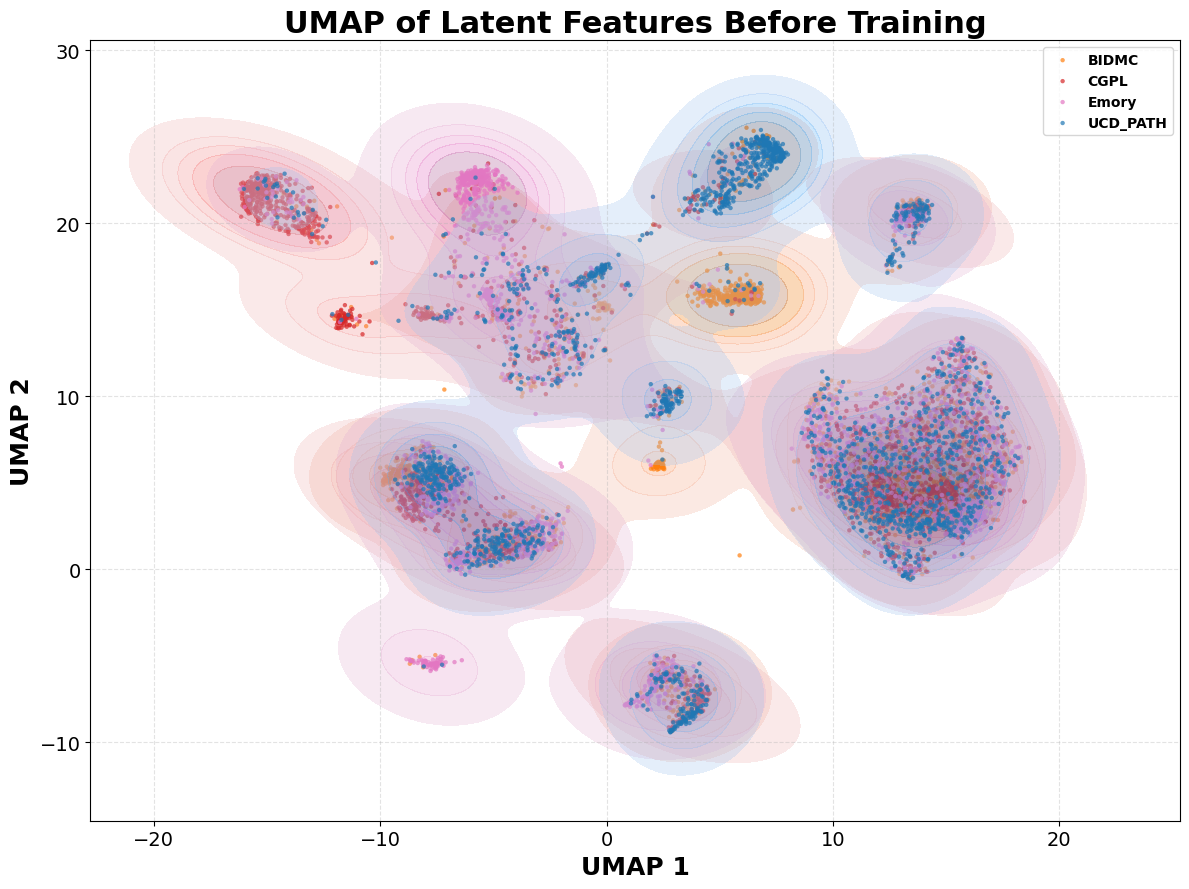

Silhouette Score (UMAP _after by clustering): 0.3896
UMAP embedding shape: (84384, 2)
Labels shape: (84384,), Unique labels: ['BIDMC' 'CGPL' 'Emory' 'UCD_PATH']


/blue/pinaki.sarder/f.afsari/conda/envs/collagen_segment/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(
/blue/pinaki.sarder/f.afsari/conda/envs/collagen_segment/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(
/blue/pinaki.sarder/f.afsari/conda/envs/collagen_segment/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(
/blue/pinaki.sarder/f.afsari/conda/envs/collagen_segment/lib/python3.12/site-packages/seaborn/distributions.py:1176: UserWarning: linewidths is ignored by contourf
  cset = contour_func(


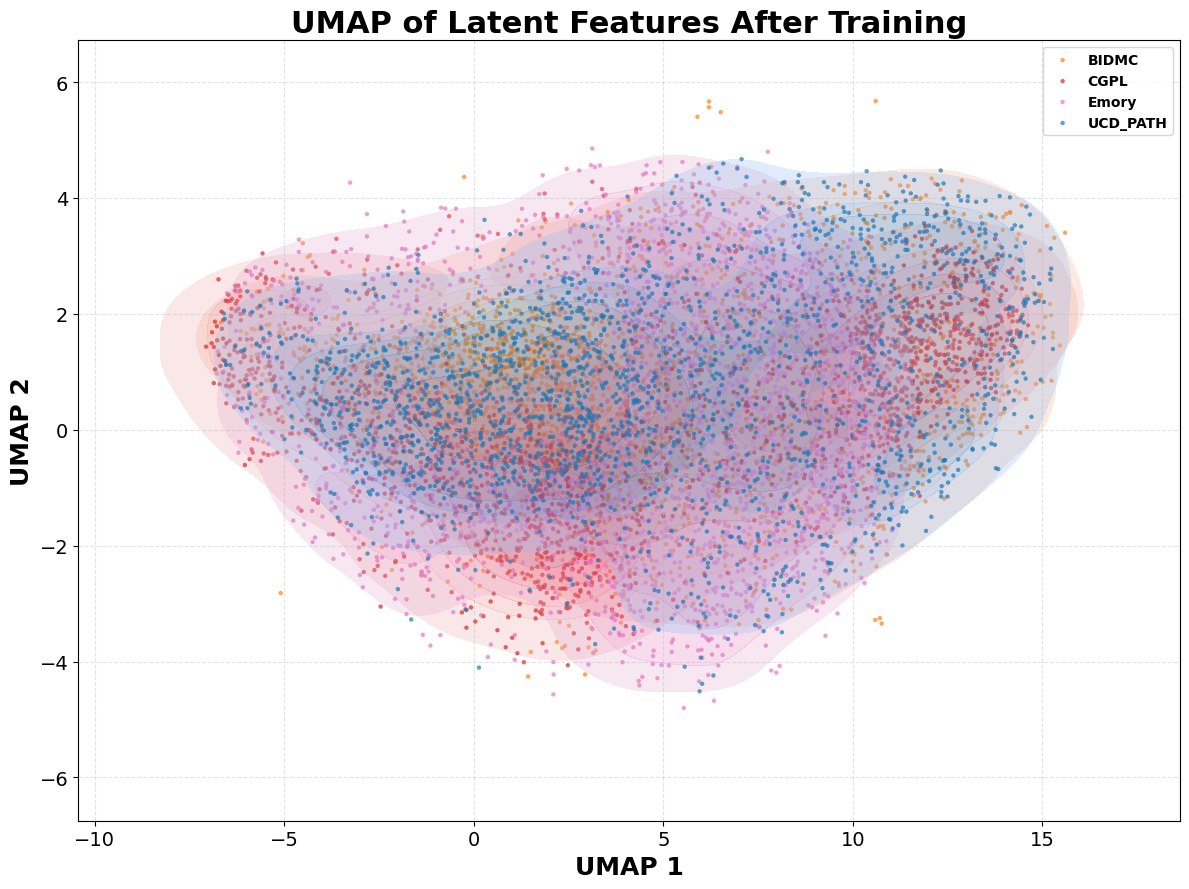

In [3]:
# ------------------ UMAP Reduction ------------------ #
def reduce_features_umap(features_dict, phase='_before'):
    features_list = []
    labels_list = []

    # Site offsets for before-training spread
    site_offsets = {
        "BIDMC": np.array([0.5, 0.0]),
        "CGPL": np.array([-0.5, 0.0]),
        "Emory": np.array([0.0, 0.5]),
        "UCD_PATH": np.array([0.0, -0.5])
    }

    for key in features_dict:
        if not key.endswith('_features'):
            continue
        feats = features_dict[key]
        site = key.replace('_features', '')

        # Add site-specific offset only for before-training
        if phase == '_before' and feats.shape[1] >= 2:
            feats[:, :2] += site_offsets.get(site, np.array([0.0, 0.0]))

        scaler = StandardScaler().fit(feats)
        feats_scaled = scaler.transform(feats)
        features_list.append(feats_scaled)
        labels_list.extend([site] * feats.shape[0])

    X_all = np.concatenate(features_list, axis=0)
    y_all = np.array(labels_list)

    if phase == '_before':
        # X_all = PCA(n_components=min(50, X_all.shape[1])).fit_transform(X_all)
        # umap_reducer = umap.UMAP(n_neighbors=10, min_dist=0.5, metric='cosine', random_state=42)
        umap_reducer = umap.UMAP(
            n_neighbors=5,
            min_dist=0.1,
            metric='cosine',
            spread=2.5,
            random_state=42,
            n_jobs=1
        )

    else:
        # umap_reducer = umap.UMAP(n_neighbors=50, min_dist=0.3, metric='euclidean', random_state=42)
        umap_reducer = umap.UMAP(
            n_neighbors=80,
            min_dist=0.9,
            metric='euclidean',
            spread=1.0,
            random_state=42,
            n_jobs=1
        )

    embedding = umap_reducer.fit_transform(X_all)

    # Silhouette score
    if phase == '_before':
        if len(np.unique(y_all)) > 1:
            sil_score = silhouette_score(embedding, y_all)
            print(f"Silhouette Score (UMAP {phase} by site): {sil_score:.4f}")
        else:
            sil_score = None
    else:
        # sil_score = silhouette_score(embedding, y_all)
        # print(f"Silhouette Score (UMAP {phase} by site): {sil_score:.4f}")
        n_clusters = min(len(np.unique(y_all)), 10)
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        cluster_labels = kmeans.fit_predict(embedding)
        if len(np.unique(cluster_labels)) > 1:
            sil_score = silhouette_score(embedding, cluster_labels)
            print(f"Silhouette Score (UMAP {phase} by clustering): {sil_score:.4f}")
        else:
            sil_score = None

    print(f"UMAP embedding shape: {embedding.shape}")
    print(f"Labels shape: {y_all.shape}, Unique labels: {np.unique(y_all)}")
    
    return embedding, y_all

def gen_plot(umap_features, labels=None, title="UMAP of latent features", phase=None):
    import seaborn as sns

    site_colors = {
        "BIDMC": "#FF7F0E",
        "CGPL": "#D62728",
        "Emory": "#E377C2",
        "UCD_PATH": "#1F77B4"
    }

    plt.figure(figsize=(12, 9))
    labels_np = np.array(labels) if labels is not None else np.array([''] * len(umap_features))

    # -----------------------------------------
    #  ARTISTIC: density contours + sparse scatter
    # -----------------------------------------

    # loop through sites
    for site in np.unique(labels_np):
        pts = umap_features[labels_np == site]
        if pts.size == 0:
            continue

        color = site_colors.get(site, 'gray')

        # --- kde density contour ---
        try:
            sns.kdeplot(
                x=pts[:, 0], y=pts[:, 1],
                levels=6,
                fill=True,
                alpha=0.28,
                color=color,
                linewidths=1.6
            )
        except Exception:
            pass  # KDE can fail for tiny datasets

        # --- sparse scatter for clarity ---
        n_show = min(2000, pts.shape[0])
        idx = np.random.choice(pts.shape[0], n_show, replace=False)

        plt.scatter(
            pts[idx, 0], pts[idx, 1],
            s=10,
            alpha=0.7,
            color=color,
            edgecolor='none',
            label=site
        )

    # --------------------
    # Cosmetics
    # --------------------
    plt.title(title, fontsize=22, fontweight='bold')
    plt.xlabel("UMAP 1", fontsize=18, fontweight='bold')
    plt.ylabel("UMAP 2", fontsize=18, fontweight='bold')

    plt.grid(True, linestyle="--", alpha=0.35)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)

    # unique legend
    handles, labels_unique = plt.gca().get_legend_handles_labels()
    by_label = dict(zip(labels_unique, handles))
    plt.legend(
        by_label.values(), by_label.keys(),
        fontsize=14,
        frameon=True,
        prop={'weight': 'bold'},
        loc='best'
    )

    plt.tight_layout()
    plt.show()
    plt.close()
    # print(f"Saved UMAP plot to: {file_path}")

embedding_before, y_all_b = reduce_features_umap(all_features_before, phase='_before')
gen_plot(embedding_before, labels=y_all_b, title="UMAP of Latent Features Before Training", phase='_before')

embedding_after, y_all_a = reduce_features_umap(all_features_after, phase='_after')
gen_plot(embedding_after, labels=y_all_a, title="UMAP of Latent Features After Training", phase='_after')

In [4]:
embed_dict = {
    'embedding_before': embedding_before,
    'labels_before': y_all_b,
    'embedding_after': embedding_after,
    'labels_after': y_all_a
}   
np.save(output_path+ '/embed_dict.npy', embed_dict)


In [5]:
# SVM classifier with train/test split on embedding_before and embedding_after
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Train/test split for embedding_before
eb_train_b, eb_test_b, y_train_b, y_test_b = train_test_split(embedding_before, y_all_b, test_size=0.2, random_state=42, stratify=y_all_b)

svm_b = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_b.fit(eb_train_b, y_train_b)
pred_b = svm_b.predict(eb_test_b)
acc_b = accuracy_score(y_test_b, pred_b)
print(f"Test accuracy on embedding_before: {acc_b:.4f}")

# Train/test split for embedding_after
eb_train_a, eb_test_a, y_train_a, y_test_a = train_test_split(embedding_after, y_all_a, test_size=0.2, random_state=42, stratify=y_all_a)

svm_a = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_a.fit(eb_train_a, y_train_a)
pred_a = svm_a.predict(eb_test_a)
acc_a = accuracy_score(y_test_a, pred_a)
print(f"Test accuracy on embedding_after: {acc_a:.4f}")


Test accuracy on embedding_before: 0.5069
Test accuracy on embedding_after: 0.5013


In [6]:
# --- New Evaluation: Train on BEFORE, Test on AFTER ---

# Ensure equal-sized splits
min_len = min(len(embedding_before), len(embedding_after))
eb_before_eq = embedding_before[:min_len]
eb_after_eq = embedding_after[:min_len]
y_eq = y_all_b[:min_len]

# Train/test split only once
X_train, X_test_before, y_train, y_test = train_test_split(
    eb_before_eq, y_eq, test_size=0.2, random_state=42, stratify=y_eq
)

# Corresponding AFTER embeddings for the same test indices
# Re-split AFTER in the same way
_, X_test_after, _, _ = train_test_split(
    eb_after_eq, y_eq, test_size=0.2, random_state=42, stratify=y_eq
)

# Train SVM on BEFORE
svm_cross = SVC(kernel='rbf', C=1.0, gamma='scale')
svm_cross.fit(X_train, y_train)

# Test on BEFORE
pred_test_before = svm_cross.predict(X_test_before)
acc_cross_before = accuracy_score(y_test, pred_test_before)
print(f"Cross-eval accuracy (Train BEFORE → Test BEFORE): {acc_cross_before:.4f}")

# Test on AFTER (critical evaluation)
pred_test_after = svm_cross.predict(X_test_after)
acc_cross_after = accuracy_score(y_test, pred_test_after)
print(f"Cross-eval accuracy (Train BEFORE → Test AFTER): {acc_cross_after:.4f}")


Cross-eval accuracy (Train BEFORE → Test BEFORE): 0.5069
Cross-eval accuracy (Train BEFORE → Test AFTER): 0.2448
